<a href="https://colab.research.google.com/github/jferreira04-cloud/Calculo_num-rico_lobosco/blob/main/atividade_19_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

José Luiz de Oliveira Ferreira - 176539


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# Sistema na forma matricial Ax = b
A = np.array([[10, -1,  2],
              [-1, 11, -1],
              [ 2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)

# Conferência da dominância diagonal por linhas
for i in range(len(A)):
    diagonal = abs(A[i, i])
    outros = np.sum(np.abs(A[i])) - diagonal
    print(f"Linha {i+1}: |a_ii| = {diagonal:.0f} > soma dos outros = {outros:.0f} ? {diagonal > outros}")

Linha 1: |a_ii| = 10 > soma dos outros = 3 ? True
Linha 2: |a_ii| = 11 > soma dos outros = 2 ? True
Linha 3: |a_ii| = 10 > soma dos outros = 3 ? True


In [6]:
def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    n = len(b)
    x = np.array(x0, dtype=float)
    historico = [(0, *x, np.nan)]  # k = 0 é a aproximação inicial (ainda sem erro)

    for k in range(1, max_iter + 1):
        x_anterior = x.copy()
        for i in range(n):
            # x[:i] já foi atualizado nesta iteração; x_anterior[i+1:] ainda é da iteração anterior
            soma = A[i, :i] @ x[:i] + A[i, i+1:] @ x_anterior[i+1:]
            x[i] = (b[i] - soma) / A[i, i]

        erro = np.max(np.abs(x - x_anterior))  # norma infinito
        historico.append((k, *x, erro))
        if erro < tol:
            return x, k, historico

    print(f"Atenção: não convergiu em {max_iter} iterações")
    return x, max_iter, historico


x0 = [0, 0, 0]
solucao, num_iteracoes, historico = gauss_seidel(A, b, x0, tol=1e-5)

print("Número de iterações:", num_iteracoes)
print(f"Solução aproximada: x = {solucao[0]:.6f}, y = {solucao[1]:.6f}, z = {solucao[2]:.6f}")

Número de iterações: 6
Solução aproximada: x = 1.000000, y = 2.000000, z = -1.000000


In [7]:
tabela = pd.DataFrame(historico, columns=["k", "x(k)", "y(k)", "z(k)", "||x(k) - x(k-1)||∞"])
tabela["k"] = tabela["k"].astype(int)

tabela.style.format(
    {"x(k)": "{:.8f}", "y(k)": "{:.8f}", "z(k)": "{:.8f}", "||x(k) - x(k-1)||∞": "{:.2e}"},
    na_rep="—",
).hide(axis="index")

k,x(k),y(k),z(k),||x(k) - x(k-1)||∞
0,0.00000000,0.00000000,0.00000000,—
1,0.60000000,2.05454545,-0.91454545,2.05e+00
2,0.98836364,2.00671074,-0.99700165,3.88e-01
3,1.00007140,2.00027907,-0.99998637,1.17e-02
4,1.00002518,2.00000353,-1.00000468,2.76e-04
5,1.00000129,1.99999969,-1.00000029,2.39e-05
6,1.00000003,1.99999998,-1.00000001,1.26e-06


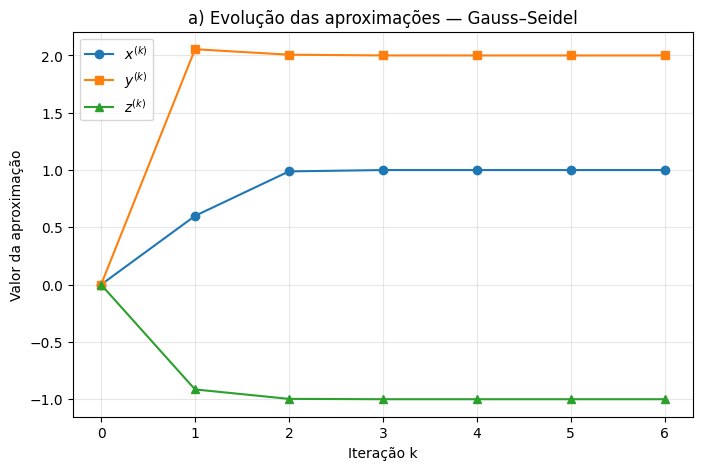

In [8]:
# a) x(k), y(k) e z(k) em função de k, no mesmo gráfico
plt.figure(figsize=(8, 5))
plt.plot(tabela["k"], tabela["x(k)"], "o-", label=r"$x^{(k)}$")
plt.plot(tabela["k"], tabela["y(k)"], "s-", label=r"$y^{(k)}$")
plt.plot(tabela["k"], tabela["z(k)"], "^-", label=r"$z^{(k)}$")
plt.xlabel("Iteração k")
plt.ylabel("Valor da aproximação")
plt.title("a) Evolução das aproximações — Gauss–Seidel")
plt.xticks(tabela["k"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

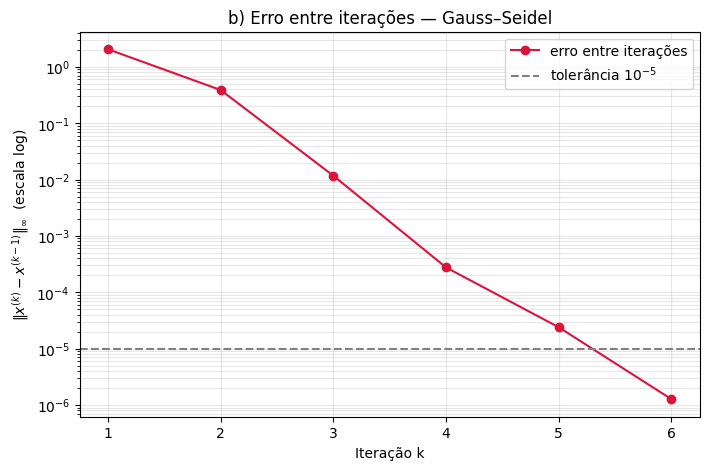

In [9]:
# b) Erro entre iterações em escala logarítmica
erros = tabela[tabela["k"] >= 1]

plt.figure(figsize=(8, 5))
plt.semilogy(erros["k"], erros["||x(k) - x(k-1)||∞"], "o-", color="crimson", label="erro entre iterações")
plt.axhline(1e-5, color="gray", linestyle="--", label=r"tolerância $10^{-5}$")
plt.xlabel("Iteração k")
plt.ylabel(r"$\|x^{(k)} - x^{(k-1)}\|_\infty$  (escala log)")
plt.title("b) Erro entre iterações — Gauss–Seidel")
plt.xticks(erros["k"])
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()